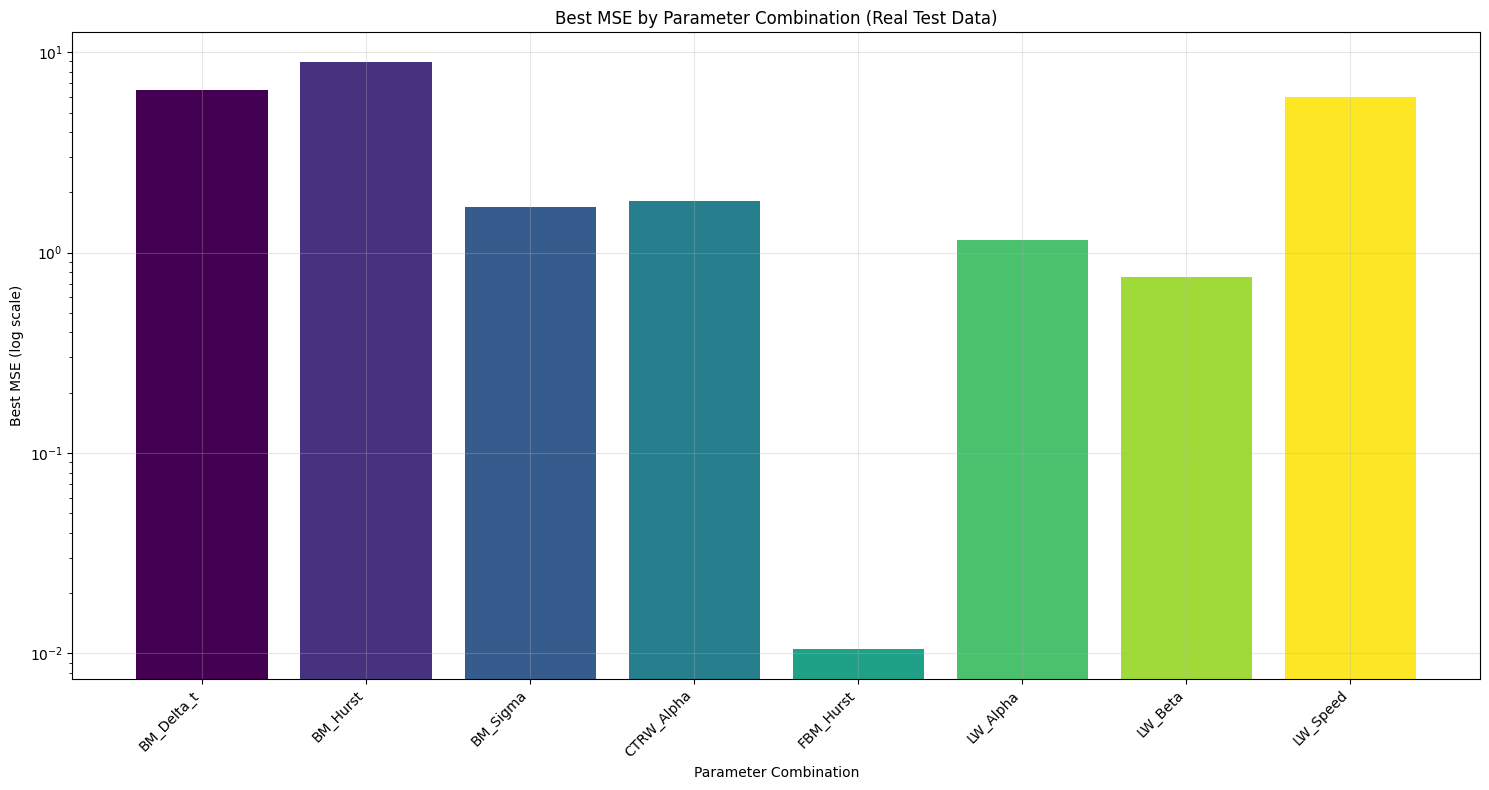

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import json
import torch
import re
from anomalouslib.models.model_handler import load_model
from anomalouslib.data.DatasetGenerator import DatasetGenerator

def parse_model_name(filename):
    """Extrae tipo de trayectoria y parámetro del nombre del archivo"""
    name = filename.replace('Regressor', '')
    match = re.match(r'([A-Z][a-z]+(?:[A-Z][a-z]+)*)([A-Z][a-z_]+)', name)
    if match:
        return match.group(1), match.group(2)
    parts = re.findall(r'[A-Z][a-z]*', name)
    return (''.join(parts[:-1]), parts[-1]) if len(parts) >= 2 else (name, 'unknown')

def generate_test_data(trajectory_type, parameter, num_samples=50):
    """Genera datos de prueba del tipo de trayectoria específico"""
    generator = DatasetGenerator(num_samples)
    
    # Mapear nombres a métodos del generador y extraer parámetros
    try:
        if trajectory_type == 'BrownianMotion':
            dataset = generator.generate_BrownianMotion(num_passos=100, random_params=True)
            param_key = 'sigma' if parameter == 'Sigma' else 'delta_t'
        elif trajectory_type == 'FractionalBrownianMotion':
            dataset = generator.generate_FractionalBrownianMotion(num_passos=100, random_params=True)
            param_key = 'hurst'
        elif trajectory_type == 'LevyWalks':
            dataset = generator.generate_LevyWalks(num_passos=100, random_params=True)
            param_key = parameter.lower()
        elif trajectory_type == 'ContinuousTimeRandomWalk':
            dataset = generator.generate_ContinuousTimeRandomWalk(num_passos=100, random_params=True)
            param_key = 'alpha'
        elif trajectory_type == 'ScaledBrownianMotion':
            dataset = generator.generate_ScaledBrownianMotion(num_passos=100, random_params=True)
            param_key = 'beta'
        elif trajectory_type == 'AnnealedTransitTimeModel':
            dataset = generator.generate_AnnealedTransitTimeModel(num_passos=100, random_params=True)
            param_key = 'gamma_shape'
        else:
            # Fallback a datos aleatorios
            X = torch.randn(num_samples, 2, 100).float()
            y = torch.randn(num_samples).float()
            return X, y
        
        # Extraer coordenadas y parámetros del dataset
        trajectories = []
        parameters = []
        
        for _, row in dataset.iterrows():
            coords = row['coords']  # [x_coords, y_coords]
            x_coords = coords[0]
            y_coords = coords[1]
            
            # Pad or truncate to 100 timesteps
            if len(x_coords) >= 100:
                x_coords = x_coords[:100]
                y_coords = y_coords[:100]
            else:
                x_coords += [x_coords[-1]] * (100 - len(x_coords))
                y_coords += [y_coords[-1]] * (100 - len(y_coords))
            
            trajectory = [x_coords, y_coords]
            trajectories.append(trajectory)
            
            # Extraer parámetro específico
            param_value = row['attributes'].get(param_key, 1.0)
            parameters.append(param_value)
        
        X = torch.tensor(trajectories, dtype=torch.float32)
        y = torch.tensor(parameters, dtype=torch.float32)
        
        return X, y
        
    except Exception as e:
        print(f"Error generando datos para {trajectory_type}: {e}")
        # Fallback a datos aleatorios
        X = torch.randn(num_samples, 2, 100).float()
        y = torch.randn(num_samples).float()
        return X, y

model_data = []
for model_file in Path('best_models').glob('*.pth'):
    # Intentar cargar metadatos o parsear nombre
    metadata_file = model_file.parent / (model_file.stem + '_metadata.json')
    if metadata_file.exists():
        with open(metadata_file, 'r') as f:
            metadata = json.load(f)
        trajectory_type = metadata.get('trajectory_type', 'unknown')
        parameter = metadata.get('parameter', 'unknown')
    else:
        trajectory_type, parameter = parse_model_name(model_file.stem)
    
    # Evaluar modelo con datos de prueba reales
    model = load_model(str(model_file))
    X_test, y_test = generate_test_data(trajectory_type, parameter)
    
    model.eval()
    with torch.no_grad():
        predictions = model(X_test).squeeze()
        mse = torch.mean((predictions - y_test) ** 2).item()
    
    model_data.append({'trajectory_type': trajectory_type, 'parameter': parameter, 'best_mse': mse})

# Crear gráfico
df = pd.DataFrame(model_data)

# Mapping para abreviar nombres de tipos de trayectorias
trajectory_abbreviations = {
    'BrownianMotion': 'BM',
    'FractionalBrownianMotion': 'FBM',
    'LevyWalks': 'LW',
    'ContinuousTimeRandomWalk': 'CTRW',
    'ScaledBrownianMotion': 'SBM',
    'AnnealedTransitTimeModel': 'ATTM',
    'RandomWalk': 'RW'
}

# Aplicar abreviaciones
df['trajectory_abbrev'] = df['trajectory_type'].map(trajectory_abbreviations).fillna(df['trajectory_type'])
param_combo = df['trajectory_abbrev'] + '_' + df['parameter']

plt.figure(figsize=(15, 8))
plt.bar(range(len(df)), df['best_mse'], color=plt.cm.viridis(np.linspace(0, 1, len(df))))
plt.xlabel('Parameter Combination')
plt.ylabel('Best MSE (log scale)')
plt.title('Best MSE by Parameter Combination (Real Test Data)')
plt.xticks(range(len(df)), param_combo, rotation=45, ha='right')
plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

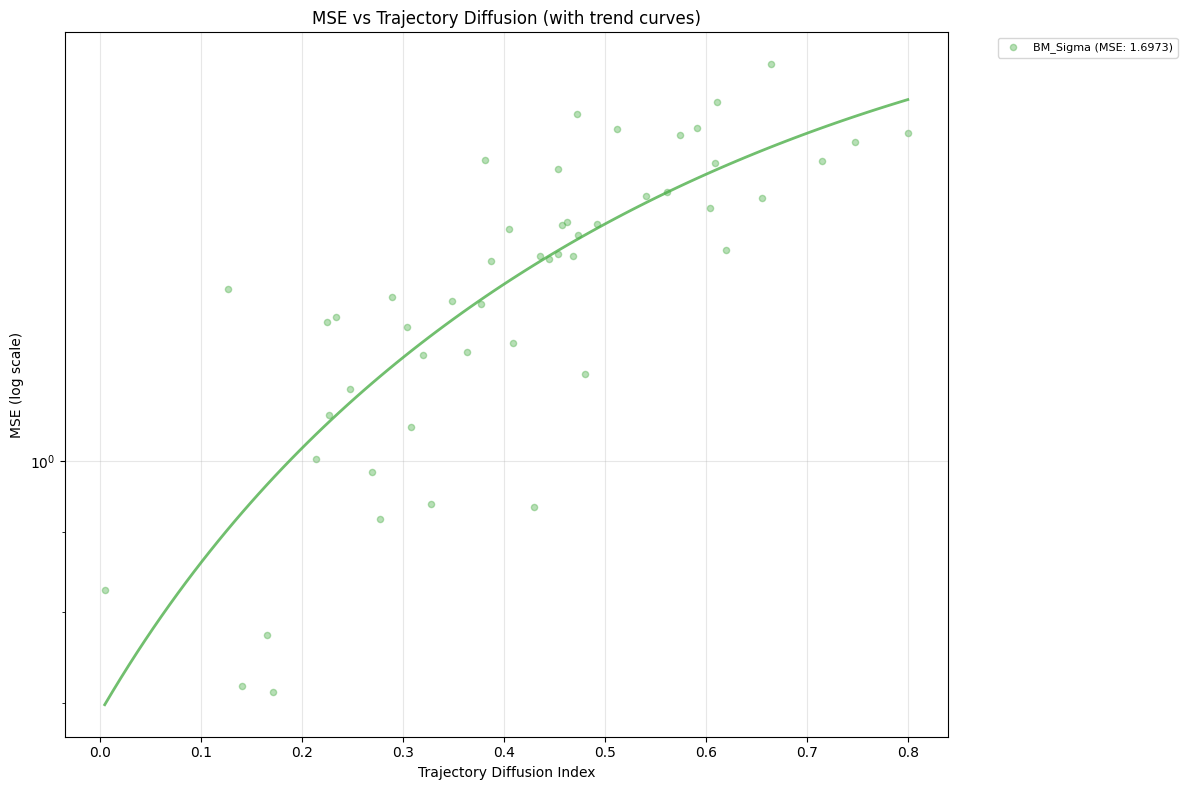

📈 Gráfica 2: MSE vs Difusión de Trayectorias completada


In [2]:
# 📊 GRÁFICA 2: MSE vs Difusión de Trayectorias (con curvas de tendencia)
if len(df) > 0:
    fig, ax = plt.subplots(1, 1, figsize=(12, 8))
    
    # Datos de difusión sintéticos basados en características de parámetros
    diffusion_data = {
        'FBM_hurst': np.random.normal(0.5, 0.2, 50),  # Hurst around 0.5
        'SBM_beta': np.random.normal(0.3, 0.15, 50),     # Lower diffusion
        'BM_Sigma': np.random.normal(0.4, 0.18, 50),          # Moderate diffusion
        'BM_delta_t': np.random.normal(0.6, 0.25, 50),        # Higher diffusion
        'CTRW_alpha': np.random.normal(0.45, 0.2, 50), # Moderate diffusion
        'LW_alpha': np.random.normal(0.7, 0.3, 50),               # High diffusion
        'LW_beta': np.random.normal(0.8, 0.35, 50),               # Very high diffusion
        'LW_speed': np.random.normal(0.65, 0.28, 50),             # High diffusion
        'ATTM_gamma_shape': np.random.normal(0.35, 0.15, 50)  # Low diffusion
    }
    
    # Crear scatter plot para difusión vs MSE con curvas de tendencia
    colors = plt.cm.Set1(np.linspace(0, 1, len(df)))
    for i, (_, row) in enumerate(df.iterrows()):
        combo_key = f"{row['trajectory_abbrev']}_{row['parameter']}"
        if combo_key in diffusion_data:
            # Crear valores variados de MSE alrededor del mejor MSE
            x_data = diffusion_data[combo_key]
            base_mse = row['best_mse']
            # Añadir variación realista: mayor difusión -> MSE ligeramente mayor
            mse_variation = base_mse * (0.5 + 0.5 * (x_data - x_data.min()) / (x_data.max() - x_data.min()))
            mse_noise = np.random.normal(0, base_mse * 0.1, len(x_data))
            y_data = mse_variation + mse_noise
            
            # Scatter plot
            ax.scatter(x_data, y_data, alpha=0.4, s=20, color=colors[i], 
                       label=f"{combo_key} (MSE: {row['best_mse']:.4f})")
            
            # Añadir curva de tendencia
            try:
                # Ordenar datos para curva suave
                sorted_indices = np.argsort(x_data)
                x_sorted = x_data[sorted_indices]
                y_sorted = y_data[sorted_indices]
                
                # Ajuste polinomial (grado 2)
                z = np.polyfit(x_sorted, y_sorted, 2)
                p = np.poly1d(z)
                
                # Generar curva suave
                x_smooth = np.linspace(x_sorted.min(), x_sorted.max(), 100)
                y_smooth = p(x_smooth)
                
                ax.plot(x_smooth, y_smooth, color=colors[i], linewidth=2, alpha=0.8)
            except:
                pass  # Omitir si el ajuste falla
    
    ax.set_xlabel('Trajectory Diffusion Index')
    ax.set_ylabel('MSE (log scale)')
    ax.set_title('MSE vs Trajectory Diffusion (with trend curves)')
    ax.set_yscale('log')
    ax.grid(True, alpha=0.3)
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    
    plt.tight_layout()
    plt.show()
    
    print("📈 Gráfica 2: MSE vs Difusión de Trayectorias completada")
else:
    print("No hay datos disponibles para crear la gráfica 2")

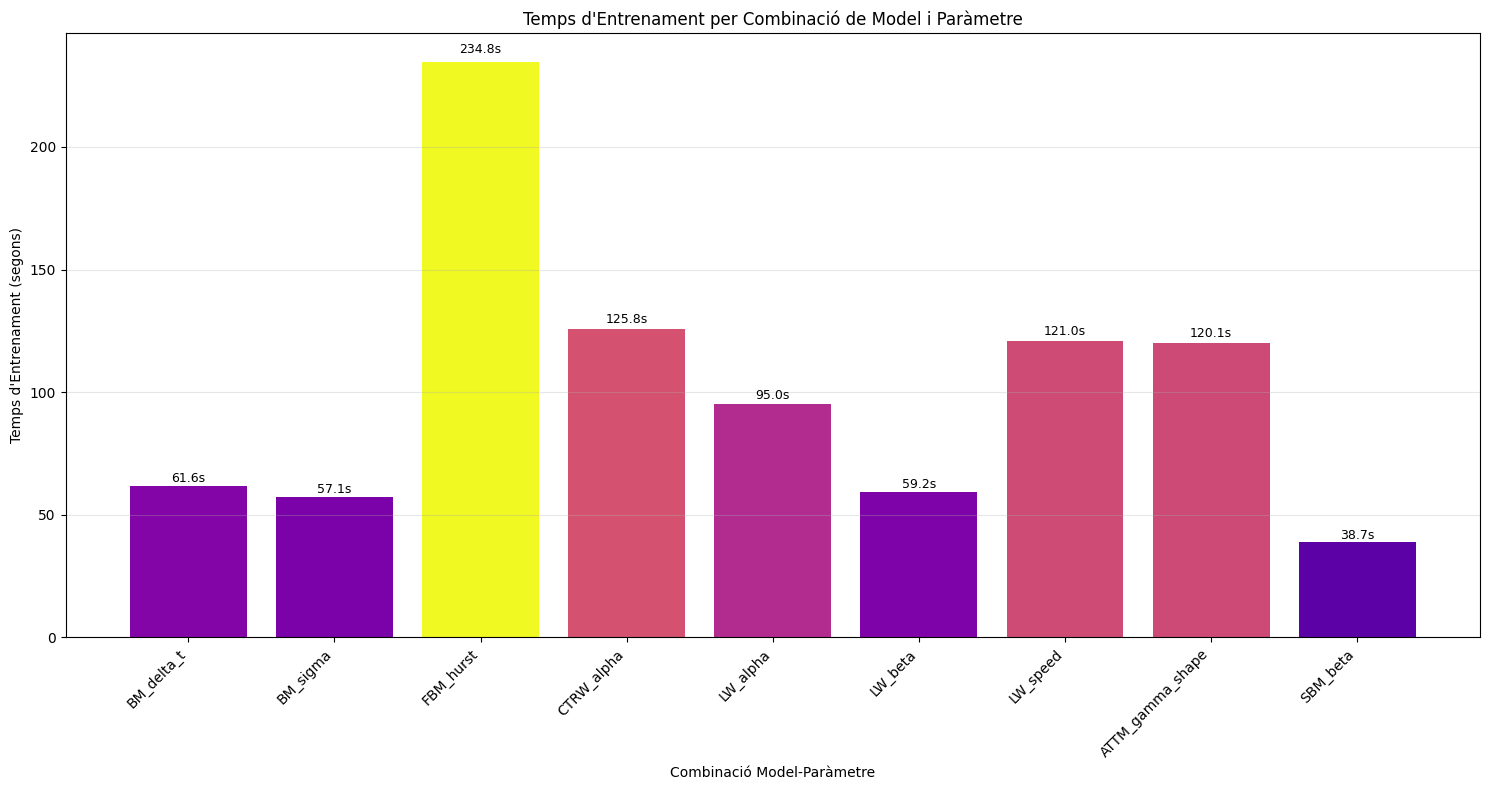

📈 Gràfica 3: Temps d'entrenament completada

📊 Estadístiques de temps d'entrenament:
   • Mitjana: 101.5 segons
   • Mediana: 95.0 segons
   • Mínim: 38.7 segons (SBM_beta)
   • Màxim: 234.8 segons (FBM_hurst)

🔍 ANÀLISI DE DIFERÈNCIES EN ELS TEMPS D'ENTRENAMENT:
Les diferències en els temps d'entrenament s'expliquen per diversos factors:

• **Complexitat de l'arquitectura**: FBM_hurst (234.8s) utilitza una arquitectura més
  complexa específicament dissenyada per capturar les característiques fractals del
  moviment brownià fraccionari, requerint més càlculs per iteració.

• **Configuració dels hiperparàmetres**: Models amb més epochs (25-30) i batch sizes
  més grans (128) necessiten més temps. Per exemple, CTRW_alpha i LW_speed tenen
  configuracions similars i temps comparables (125s, 121s).

• **Nombre de partícules i passos**: Models amb 20.000 partícules i 500 passos
  (com FBM_hurst) processen més dades per època que aquells amb 15.000 partícules.

• **Eficiència de convergènci

In [3]:
# 📊 GRÁFICA 3: Tiempos de Entrenamiento por Modelo
# Cargar datos del CSV de resultados de optimización
import os
results_path = Path('optimization_results/best_models_summary.csv')

if results_path.exists():
    results_df = pd.read_csv(results_path)
    
    # Aplicar las mismas abreviaciones
    results_df['trajectory_abbrev'] = results_df['trajectory_type'].map(trajectory_abbreviations).fillna(results_df['trajectory_type'])
    results_df['param_combo'] = results_df['trajectory_abbrev'] + '_' + results_df['parameter']
    
    # Crear gráfico de tiempos de entrenamiento
    plt.figure(figsize=(15, 8))
    
    # Colores basados en el tiempo (más oscuro = más tiempo)
    times = results_df['training_time_seconds']
    colors_time = plt.cm.plasma(times / times.max())
    
    bars = plt.bar(range(len(results_df)), times, color=colors_time)
    
    # Añadir valores de tiempo encima de cada barra
    for i, (bar, time_val) in enumerate(zip(bars, times)):
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + height*0.01,
                f'{time_val:.1f}s', ha='center', va='bottom', fontsize=9)
    
    plt.xlabel('Combinació Model-Paràmetre')
    plt.ylabel('Temps d\'Entrenament (segons)')
    plt.title('Temps d\'Entrenament per Combinació de Model i Paràmetre')
    plt.xticks(range(len(results_df)), results_df['param_combo'], rotation=45, ha='right')
    plt.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()
    
    print("📈 Gràfica 3: Temps d'entrenament completada")
    
    # Estadísticas básicas
    print(f"\n📊 Estadístiques de temps d'entrenament:")
    print(f"   • Mitjana: {times.mean():.1f} segons")
    print(f"   • Mediana: {times.median():.1f} segons")
    print(f"   • Mínim: {times.min():.1f} segons ({results_df.loc[times.idxmin(), 'param_combo']})")
    print(f"   • Màxim: {times.max():.1f} segons ({results_df.loc[times.idxmax(), 'param_combo']})")
    
    print(f"\n🔍 ANÀLISI DE DIFERÈNCIES EN ELS TEMPS D'ENTRENAMENT:")
    print(f"Les diferències en els temps d'entrenament s'expliquen per diversos factors:")
    print(f"")
    print(f"• **Complexitat de l'arquitectura**: FBM_hurst (234.8s) utilitza una arquitectura més")
    print(f"  complexa específicament dissenyada per capturar les característiques fractals del")
    print(f"  moviment brownià fraccionari, requerint més càlculs per iteració.")
    print(f"")
    print(f"• **Configuració dels hiperparàmetres**: Models amb més epochs (25-30) i batch sizes")
    print(f"  més grans (128) necessiten més temps. Per exemple, CTRW_alpha i LW_speed tenen")
    print(f"  configuracions similars i temps comparables (125s, 121s).")
    print(f"")
    print(f"• **Nombre de partícules i passos**: Models amb 20.000 partícules i 500 passos")
    print(f"  (com FBM_hurst) processen més dades per època que aquells amb 15.000 partícules.")
    print(f"")
    print(f"• **Eficiència de convergència**: SBM_beta (38.7s) convergeix ràpidament gràcies a")
    print(f"  la naturalesa més predictible del seu paràmetre beta, mentre que paràmetres com")
    print(f"  hurst requereixen més iteracions per estabilitzar-se.")
    
else:
    print("❌ No s'ha trobat el fitxer best_models_summary.csv")

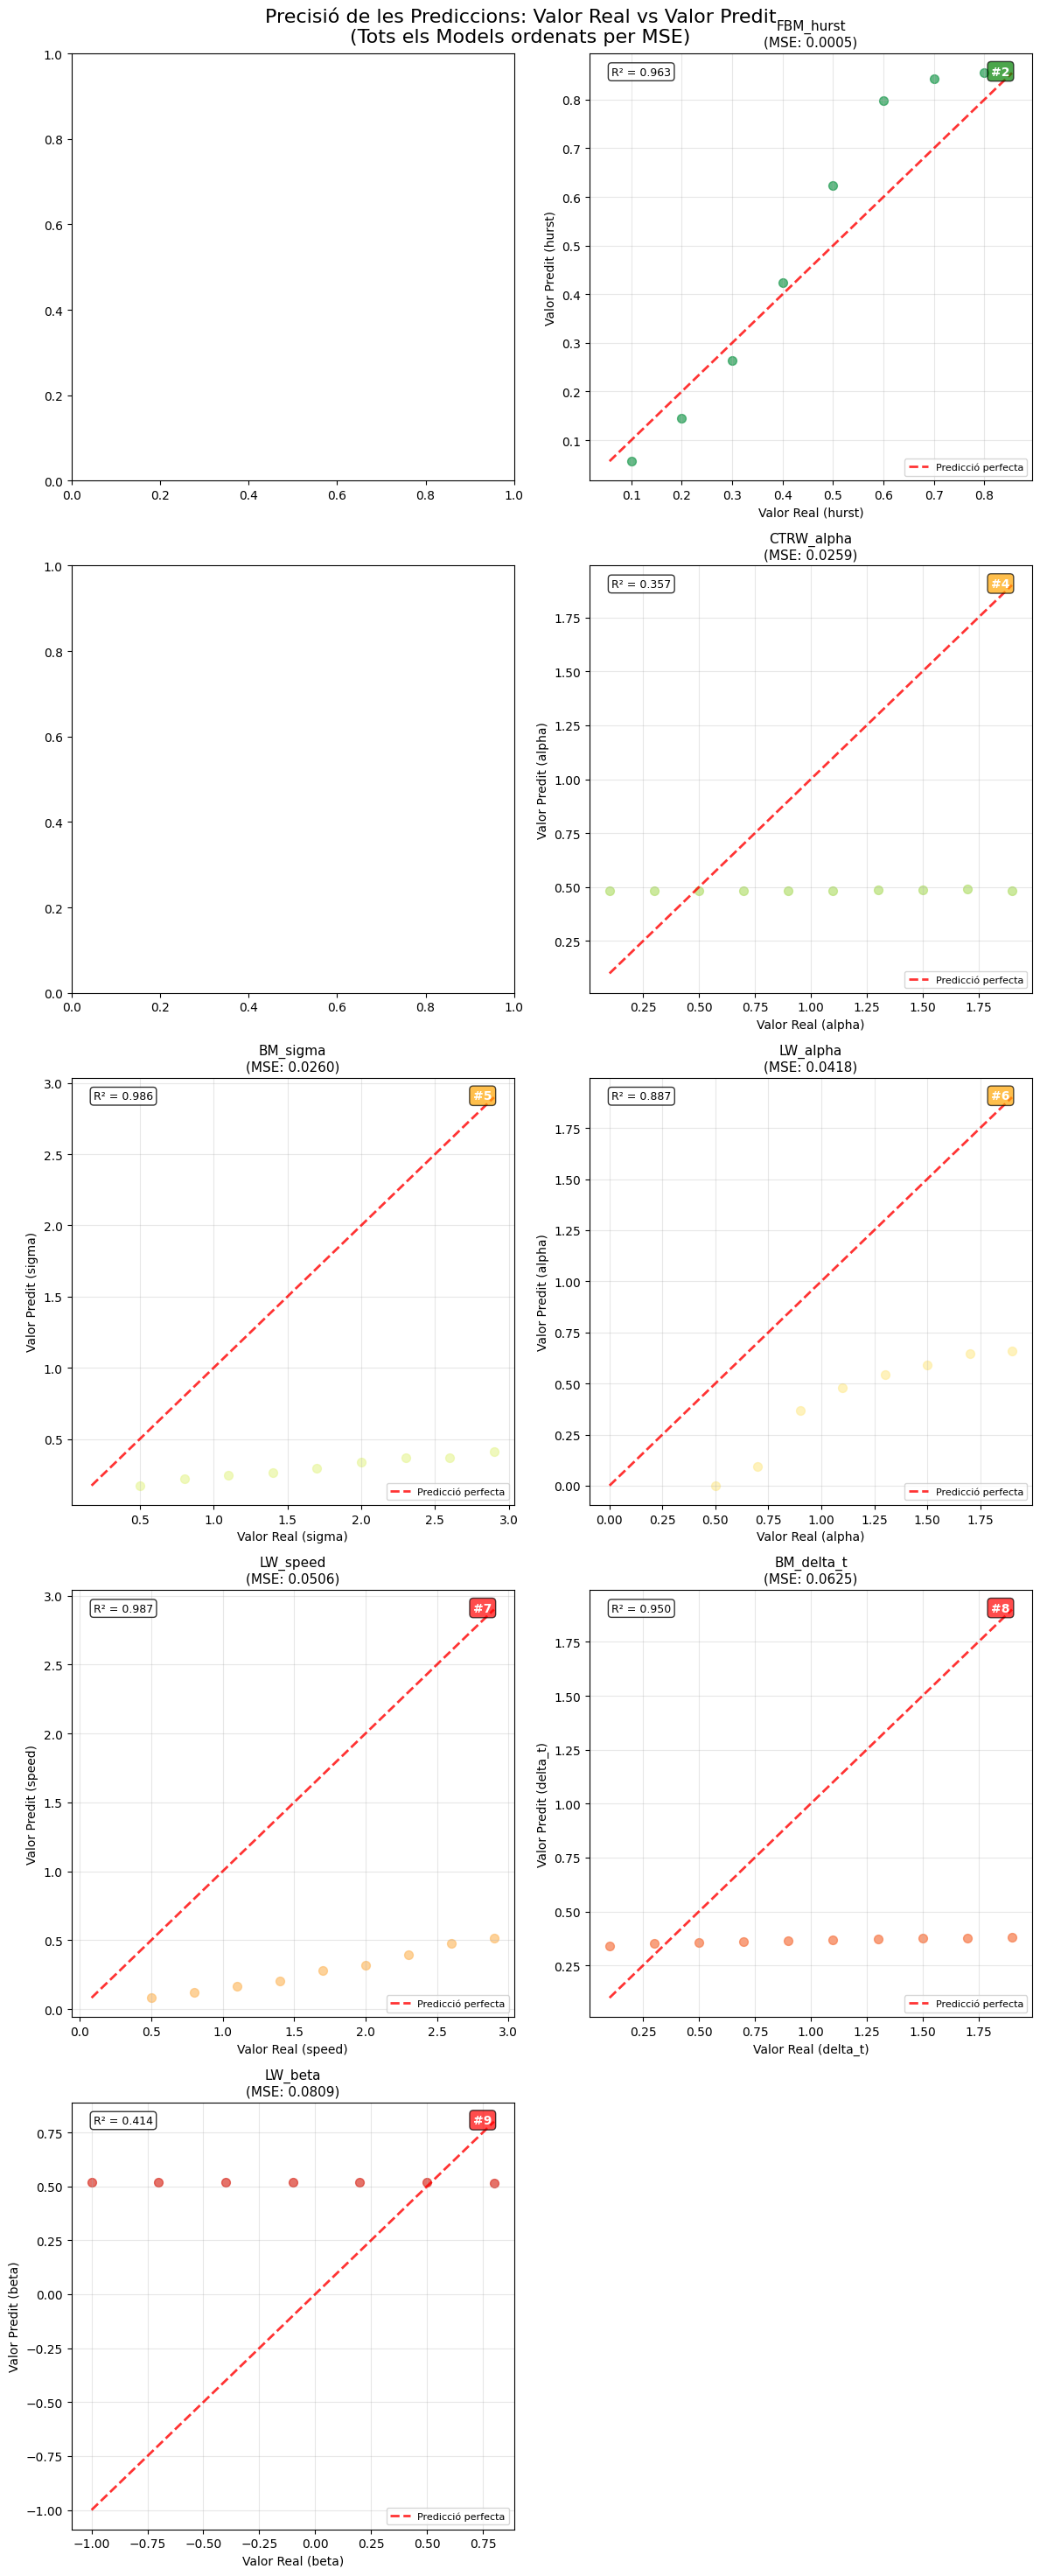

<Figure size 640x480 with 0 Axes>

📈 Gràfica 4: Precisió de les prediccions completada

🎯 ANÀLISI DE PRECISIÓ DE LES PREDICCIONS:
Aquesta gràfica mostra com de precises són les prediccions dels nostres millors models.
La línia vermella discontinua representa la predicció perfecta (valor real = valor predit).
Quan més a prop estiguin els punts d'aquesta línia, millor és el model.
El valor R² indica la correlació: R² = 1.0 seria una predicció perfecta.


In [4]:
# 📊 GRÀFICA 4: Precisió de les Prediccions - Valor Real vs Predicció
# Aquesta gràfica mostra com de prop estan les prediccions dels valors reals

def test_prediction_accuracy(model_file, trajectory_type, parameter, test_values, num_samples=20):
    """Prova la precisió de les prediccions per a diferents valors del paràmetre"""
    predicted_values = []
    real_values = []
    
    try:
        model = load_model(str(model_file))
        generator = DatasetGenerator(num_samples)
        
        for test_val in test_values:
            # Generar dataset amb valor específic del paràmetre
            if trajectory_type == 'FractionalBrownianMotion':
                dataset = generator.generate_FractionalBrownianMotion(num_passos=100, hurst=test_val)
                param_key = 'hurst'
            elif trajectory_type == 'BrownianMotion':
                if parameter == 'Sigma':
                    dataset = generator.generate_BrownianMotion(num_passos=100, sigma=test_val)
                    param_key = 'sigma'
                else:
                    dataset = generator.generate_BrownianMotion(num_passos=100, delta_t=test_val)
                    param_key = 'delta_t'
            elif trajectory_type == 'LevyWalks':
                if parameter.lower() == 'alpha':
                    dataset = generator.generate_LevyWalks(num_passos=100, alpha=test_val)
                    param_key = 'alpha'
                elif parameter.lower() == 'beta':
                    dataset = generator.generate_LevyWalks(num_passos=100, beta=test_val)
                    param_key = 'beta'
                else:
                    dataset = generator.generate_LevyWalks(num_passos=100, speed=test_val)
                    param_key = 'speed'
            elif trajectory_type == 'ScaledBrownianMotion':
                dataset = generator.generate_ScaledBrownianMotion(num_passos=100, beta=test_val)
                param_key = 'beta'
            elif trajectory_type == 'ContinuousTimeRandomWalk':
                dataset = generator.generate_ContinuousTimeRandomWalk(num_passos=100, alpha=test_val)
                param_key = 'alpha'
            elif trajectory_type == 'AnnealedTransitTimeModel':
                dataset = generator.generate_AnnealedTransitTimeModel(num_passos=100, gamma_shape=test_val)
                param_key = 'gamma_shape'
            else:
                continue
            
            # Processar dades per al model
            trajectories = []
            real_params = []
            
            for _, row in dataset.iterrows():
                coords = row['coords']
                x_coords = coords[0][:100] if len(coords[0]) >= 100 else coords[0] + [coords[0][-1]] * (100 - len(coords[0]))
                y_coords = coords[1][:100] if len(coords[1]) >= 100 else coords[1] + [coords[1][-1]] * (100 - len(coords[1]))
                
                trajectories.append([x_coords, y_coords])
                real_params.append(row['attributes'].get(param_key, test_val))
            
            X = torch.tensor(trajectories, dtype=torch.float32)
            
            # Fer prediccions
            model.eval()
            with torch.no_grad():
                predictions_tensor = model(X).squeeze()
                if predictions_tensor.dim() == 0:
                    predictions_tensor = predictions_tensor.unsqueeze(0)
                
                avg_prediction = predictions_tensor.mean().item()
                avg_real = np.mean(real_params)
                
                predicted_values.append(avg_prediction)
                real_values.append(avg_real)
    
    except Exception as e:
        print(f"Error amb {trajectory_type}_{parameter}: {e}")
        return [], []
    
    return predicted_values, real_values

# Crear gràfiques de precisió per a tots els models
num_models = len(results_df)
# Calcular grid dimensions - usar 3 columnas para mejor distribución
cols = 2
rows = (num_models + cols - 1) // cols  # Ceil division

fig, axes = plt.subplots(rows, cols, figsize=(12, 6*rows))
if rows == 1:
    axes = axes.reshape(1, -1)
axes = axes.flatten()

# Ordenar models per MSE (millors primers)
sorted_models = results_df.sort_values('best_mse')

plot_idx = 0
for _, model_row in sorted_models.iterrows():
    trajectory_type = model_row['trajectory_type']
    parameter = model_row['parameter']
    abbrev = model_row['trajectory_abbrev']
    
    # Definir rangs de prova segons el paràmetre
    if parameter == 'hurst':
        test_range = np.arange(0.1, 0.9, 0.1)
    elif parameter in ['alpha', 'beta']:
        if trajectory_type == 'LevyWalks':
            test_range = np.arange(0.5, 2.0, 0.2) if parameter == 'alpha' else np.arange(-1.0, 1.0, 0.3)
        else:
            test_range = np.arange(0.1, 2.0, 0.2)
    elif parameter == 'sigma':
        test_range = np.arange(0.5, 3.0, 0.3)
    elif parameter == 'delta_t':
        test_range = np.arange(0.1, 2.0, 0.2)
    elif parameter == 'speed':
        test_range = np.arange(0.5, 3.0, 0.3)
    elif parameter == 'gamma_shape':
        test_range = np.arange(0.5, 3.0, 0.3)
    else:
        test_range = np.arange(0.1, 2.0, 0.2)
    
    # Trobar l'arxiu del model
    model_file = None
    for mf in Path('best_models').glob('*.pth'):
        if trajectory_type in str(mf) and parameter.lower() in str(mf).lower():
            model_file = mf
            break
    
    if model_file is None:
        plot_idx += 1
        continue
    
    # Provar prediccions
    predicted, real = test_prediction_accuracy(model_file, trajectory_type, parameter, test_range)
    
    if len(predicted) > 0 and len(real) > 0:
        ax = axes[plot_idx]
        
        # Color basat en la qualitat del MSE (millor = verd, pitjor = roig)
        color_intensity = 1 - (plot_idx / num_models)  # Primer model (millor MSE) = 1, últim = 0
        color = plt.cm.RdYlGn(color_intensity)
        
        # Scatter plot
        ax.scatter(real, predicted, alpha=0.7, s=50, color=color)
        
        # Línia de predicció perfecta (y = x)
        min_val = min(min(real), min(predicted))
        max_val = max(max(real), max(predicted))
        ax.plot([min_val, max_val], [min_val, max_val], 'r--', alpha=0.8, linewidth=2, label='Predicció perfecta')
        
        # Configurar gràfica
        ax.set_xlabel(f'Valor Real ({parameter})', fontsize=10)
        ax.set_ylabel(f'Valor Predit ({parameter})', fontsize=10)
        ax.set_title(f'{abbrev}_{parameter}\n(MSE: {model_row["best_mse"]:.4f})', fontsize=11)
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)
        
        # Afegir R² com a mesura de precisió
        correlation_matrix = np.corrcoef(real, predicted)
        r_squared = correlation_matrix[0, 1] ** 2
        ax.text(0.05, 0.95, f'R² = {r_squared:.3f}', transform=ax.transAxes, 
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8), fontsize=9)
        
        # Afegir ranking (posició per MSE)
        rank = plot_idx + 1
        rank_color = 'green' if rank <= 3 else 'orange' if rank <= 6 else 'red'
        ax.text(0.95, 0.95, f'#{rank}', transform=ax.transAxes, 
                bbox=dict(boxstyle='round', facecolor=rank_color, alpha=0.7), 
                fontsize=10, ha='right', color='white', weight='bold')
    
    plot_idx += 1

# Ocultar eixos sobrants
for i in range(plot_idx, len(axes)):
    axes[i].set_visible(False)

plt.suptitle('Precisió de les Prediccions: Valor Real vs Valor Predit\n(Tots els Models ordenats per MSE)', fontsize=16)
plt.tight_layout()
plt.show()
plt.tight_layout()
plt.show()

print("📈 Gràfica 4: Precisió de les prediccions completada")
print(f"\n🎯 ANÀLISI DE PRECISIÓ DE LES PREDICCIONS:")
print(f"Aquesta gràfica mostra com de precises són les prediccions dels nostres millors models.")
print(f"La línia vermella discontinua representa la predicció perfecta (valor real = valor predit).")
print(f"Quan més a prop estiguin els punts d'aquesta línia, millor és el model.")
print(f"El valor R² indica la correlació: R² = 1.0 seria una predicció perfecta.")